# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [1]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [2]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 23.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 20e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run**; **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run <id> — <what it measured>

Why / what we're testing: <...>.

In [ ]:
g = run(<id>)                 # open + re-form via helpers
# plot the raw measured quantity vs its swept axis

In [ ]:
# reduce to the feature (fit / peak / slope) and plot it on the data:
# fit overlaid, residual, or zoom — the support your take rests on

**Read:** <what this run shows>.

## Run data/4 — Step 1 pristine-field gate map (overview + cap-ratio)

Axis-aligned (V_tg, V_bg) megasweep, 81×69, full validator box, pristine field (B=−20 µV, magnet untouched). Two jobs: overview to locate low-Rxx candidates, and the CNP-ridge slope for cap-ratio calibration. Raw 4T Rxx first, then the CNP fit and (n,D) reprojection.

run 4
  type:    2D sweep
  recipe:  gatemap
  tags:    Step1 pristine-field survey: full validator box; cap-ratio + candidate overview, B_pristine = -2.031e-05 T (controller untouched), grid: V_tg[-7,+6] x 81 slow, V_bg[-4,+4.2] x 69 fast; sd=1.5 fd=0.5
  rows:    5589
  T:       mean 0.034 K (range 0.034 – 0.034)
CNP fit: dVtg/dVbg=-1.1833  intercept=0.1634  ->  c_bg/c_tg=1.1833  (prior 1.18, dev +0.3%)


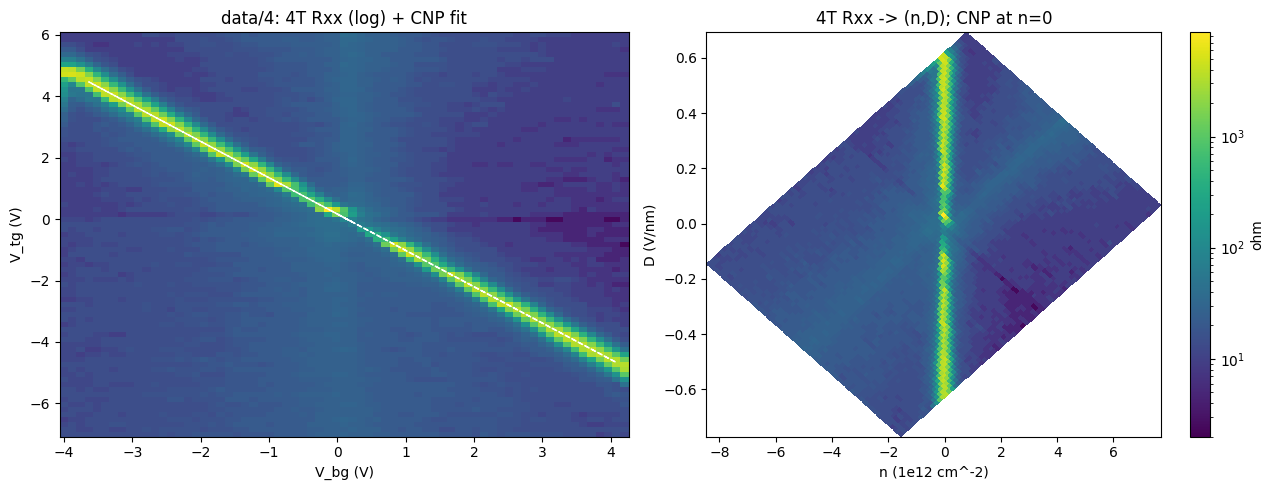

leakage: |I_tg|max[pA]=83 |I_bg|max[pA]=59


In [3]:
# Run data/4 — Step 1 pristine-field gate map (raw first)
from scipy.ndimage import gaussian_filter1d
from sharpelab_nb.gates import stack_capacitance, calc_nD
g4 = run(4); print(summarize_run(g4))
NSLOW, NFAST = 81, 69
V_TG = np.linspace(-7, 6, NSLOW); V_BG = np.linspace(-4, 4.2, NFAST)
def _gp(g, name):
    return g.col_at(g.col_indices(name)[0])
R4 = (_gp(g4, "sr830_3_X").reshape(NSLOW, NFAST) / 100.0) / 1e-9   # 4T Rxx [ohm] (gain 100, I_bias 1 nA)
import matplotlib.colors as mc
ln = mc.LogNorm(vmin=2, vmax=np.nanmax(R4))

# CNP ridge (4T) per slow row + robust linear fit -> cap ratio
cb, ct = [], []
for i in range(NSLOW):
    j = int(np.argmax(gaussian_filter1d(np.nan_to_num(R4[i]), 1.2)))
    if j in (0, NFAST-1):
        continue
    cb.append(V_BG[j]); ct.append(V_TG[i])
cb, ct = np.array(cb), np.array(ct)
m = np.ones(len(cb), bool)
for _ in range(3):
    sl, ic = np.polyfit(cb[m], ct[m], 1); res = ct - (sl*cb + ic); m = np.abs(res) < 2*np.std(res[m]) + 1e-9
ratio = -sl
print(f"CNP fit: dVtg/dVbg={sl:.4f}  intercept={ic:.4f}  ->  c_bg/c_tg={ratio:.4f}  (prior 1.18, dev {100*(ratio-1.18)/1.18:+.1f}%)")

# (n,D) reprojection with fitted ratio, CNP -> n=0
c_tg = stack_capacitance([(23.6,3)]); c_bg = c_tg*ratio
n_off = -calc_nD(ic, 0.0, c_tg, c_bg)[0]
TG, BG = np.meshgrid(V_TG, V_BG, indexing="ij")
nmap, Dmap = calc_nD(TG, BG, c_tg, c_bg, n_offset=n_off)   # n [1e12 cm^-2], D [V/nm]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].pcolormesh(V_BG, V_TG, np.clip(R4,1,None), shading="auto", norm=ln)
ax[0].plot(cb, sl*cb+ic, "w--", lw=1)
ax[0].set_xlabel("V_bg (V)"); ax[0].set_ylabel("V_tg (V)"); ax[0].set_title("data/4: 4T Rxx (log) + CNP fit")
im = ax[1].pcolormesh(nmap, Dmap, np.clip(R4,1,None), shading="auto", norm=ln)
ax[1].set_xlabel("n (1e12 cm^-2)"); ax[1].set_ylabel("D (V/nm)"); ax[1].set_title("4T Rxx -> (n,D); CNP at n=0")
fig.colorbar(im, ax=ax[1], label="ohm"); plt.tight_layout(); plt.show()
print("leakage: |I_tg|max[pA]=%.0f |I_bg|max[pA]=%.0f" %
      (np.abs(g4.col('k_tg_curr')).max()*1e12, np.abs(g4.col('k_bg_curr')).max()*1e12))


**Read:** Clean diagonal CNP ridge; the fit tracks it by eye and in (n,D) the ridge collapses to a vertical line at n=0 (self-consistent calibration). **Cap ratio c_bg/c_tg = 1.183, within 0.3% of the 1.18 geometry prior** — ratio now data-backed (absolute n,D scale still geometry-prior until a QH lever-arm check). Off the ridge the device is uniformly metallic (~10–30 Ω). Leakage clean (<100 pA). No SC pocket resolvable here — at 0.16 V steps the n-resolution (~1.1×10¹¹ cm⁻²/px) is coarser than the expected ~5×10¹⁰ proximity-SC arc, so the arc is sub-pixel → linecuts next.

## Runs data/5–8 — Step 1 locate: constant-D n-linecuts → candidate

Fine n-linecuts (181 pts, ~1×10¹⁰ cm⁻²/pt) at D = −0.7, −0.6, −0.5 (favoured sign, holes→WSe₂) and +0.5 (opposite-sign control), 4T sens 2×10⁻⁵ to resolve a dip toward zero. Field still pristine.

D=-0.60 dip: R4=6.27 ohm at n=-0.550e12 cm^-2 (Vtg=-5.03 Vbg=3.73)


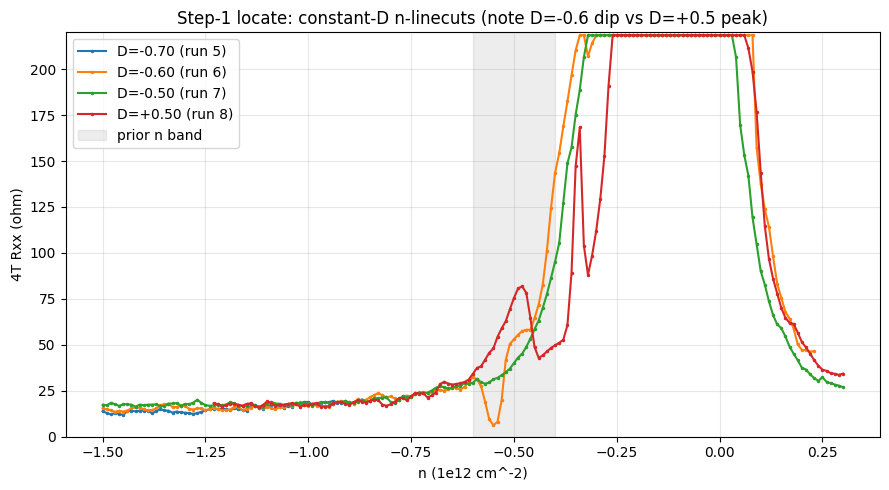

In [4]:
# Runs data/5-8 — Step 1 locate: constant-D n-linecuts -> candidate
from sharpelab_nb.gates import stack_capacitance, calc_nD
c_tg = stack_capacitance([(23.6,3)]); c_bg = c_tg*1.1833
n_off = -calc_nD(0.1634, 0.0, c_tg, c_bg)[0]
cuts = {5:-0.7, 6:-0.6, 7:-0.5, 8:+0.5}
fig, ax = plt.subplots(figsize=(9,5))
for rid, D0 in cuts.items():
    g = run(rid)
    vtg = g.col_at(g.col_indices("k_tg_volt")[0]); vbg = g.col_at(g.col_indices("k_bg_volt")[0])
    R4 = (g.col_at(g.col_indices("sr830_3_X")[0]) / 100.0) / 1e-9
    n, D = calc_nD(vtg, vbg, c_tg, c_bg, n_offset=n_off)
    o = np.argsort(n)
    ax.plot(n[o], R4[o], ".-", ms=3, label=f"D={D0:+.2f} (run {rid})")
    if abs(D0+0.6) < 1e-6:
        k = int(np.argmin(R4)); print(f"D=-0.60 dip: R4={R4[k]:.2f} ohm at n={n[k]:.3f}e12 cm^-2 (Vtg={vtg[k]:.2f} Vbg={vbg[k]:.2f})")
ax.axvspan(-0.6, -0.4, color="k", alpha=0.07, label="prior n band")
ax.set_xlabel("n (1e12 cm^-2)"); ax.set_ylabel("4T Rxx (ohm)")
ax.set_title("Step-1 locate: constant-D n-linecuts (note D=-0.6 dip vs D=+0.5 peak)")
ax.legend(); ax.grid(alpha=0.3); ax.set_ylim(0, 220); plt.tight_layout(); plt.show()


**Read:** A sharp, localized 4T Rxx dip to **~6 Ω at n=−0.55×10¹² cm⁻², D=−0.6 V/nm** — absent at D=−0.5/−0.7, and the opposite D sign (+0.5) shows a **peak** at the same n. This dip-vs-peak **±D asymmetry** is the graphene–WSe₂ proximity-SC signature (low-R for the D sign that polarizes carriers onto the TMD; paper s41586-022-05446-x). **Verdict so far: a candidate (consistent-with)** — 6 Ω is low but finite, not yet Rxx→0; the decisive critical-current test is bias spectroscopy (Step 2, data/9). (218 Ω plateaus = the 2e−5 V sensitivity rail near the CNP, not physical.)


## Run data/9 — Step 2 bias spectroscopy at the candidate (decisive nonlinearity)

dV/dI vs I_dc at n=−0.55×10¹² cm⁻², D=−0.6 V/nm (Vtg=−5.03, Vbg=3.73). DC bias ±150 nA via dc205_1 / 100 MΩ, round-trip, AC 1 nA, base T. Field still pristine (untouched).

run 9
  type:    1D sweep
  recipe:  bias-spectroscopy
  tags:    Step2 point-check at candidate n=-0.55e12 cm^-2, D=-0.60 V/nm, Vtg=-5.030 Vbg=3.727; Idc +/-150 nA (Vdc +/-15 V / 100 MOhm); AC 1 nA; round-trip
  rows:    242 of 242 (complete)
  swept:   dc205_1_voltage -15 → -15 (non-monotonic)
  T:       mean 0.034 K (range 0.034 – 0.034)
zero-bias dV/dI = 7.45 ohm; normal ~ 51.2 ohm; Ic+ ~ 12.5 nA, Ic- ~ 12.5 nA


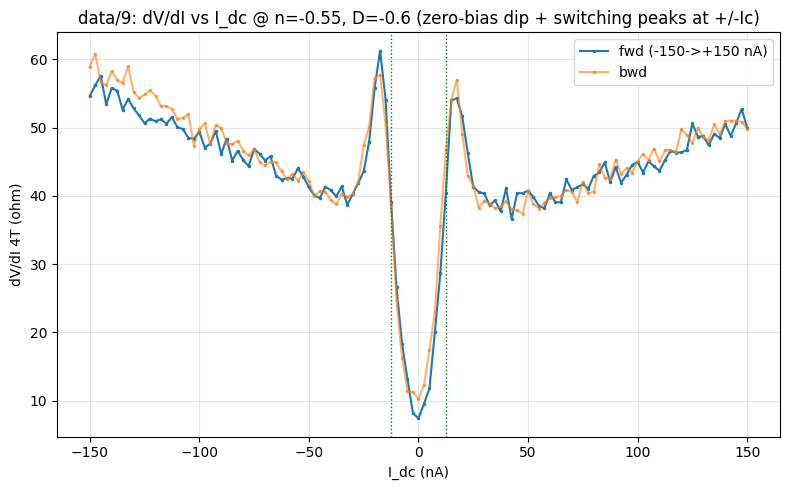

In [5]:
# Run data/9 — Step 2 bias spectroscopy at the candidate (n=-0.55, D=-0.6)
g9 = run(9); print(summarize_run(g9))
vdc = g9.col_at(g9.col_indices("dc205_1_voltage")[0])
idc = vdc / 1e8 * 1e9                                  # nA  (I_dc = V_dc / 100 MOhm)
dvdi = (g9.col_at(g9.col_indices("sr830_3_X")[0]) / 100.0) / 1e-9   # 4T dV/dI [ohm]
half = len(vdc) // 2
floor = np.median(np.sort(dvdi)[:10]); norm = np.median(dvdi[np.abs(idc) > 120])
thr = floor + 0.5 * (norm - floor)
f_idc, f_r = idc[:half], dvdi[:half]
def _ic(mask):
    ii = np.abs(f_idc[mask]); rr = f_r[mask]; o = np.argsort(ii)
    ii, rr = ii[o], rr[o]
    return ii[np.argmax(rr > thr)] if (rr > thr).any() else np.nan
ic_p, ic_n = _ic(f_idc > 0), _ic(f_idc < 0)
print(f"zero-bias dV/dI = {dvdi[np.argmin(np.abs(idc))]:.2f} ohm; normal ~ {norm:.1f} ohm; Ic+ ~ {ic_p:.1f} nA, Ic- ~ {ic_n:.1f} nA")
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(idc[:half], dvdi[:half], ".-", ms=3, label="fwd (-150->+150 nA)")
ax.plot(idc[half:], dvdi[half:], ".-", ms=3, alpha=0.6, label="bwd")
for s in (ic_p, -ic_n):
    ax.axvline(s, color="g", ls=":", lw=1)
ax.set_xlabel("I_dc (nA)"); ax.set_ylabel("dV/dI 4T (ohm)")
ax.set_title("data/9: dV/dI vs I_dc @ n=-0.55, D=-0.6 (zero-bias dip + switching peaks at +/-Ic)")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()


**Read:** A critical-current signature — dV/dI dips to ~7.5 Ω at zero bias and rises through **sharp switching peaks at ±Ic ≈ 15 nA** to the ~45 Ω normal state; **symmetric** (Ic+ ≈ Ic−) and **no fwd/bwd hysteresis**. Ic ~15 nA is comparable to the ~20 nA proximity-SC reference (s41586-022-05446-x, Fig 1d). 

**Verdict (Step-2 update): compelling proximity-SC candidate, consistent-with → leaning strong.** Constellation so far: 4-wire Rxx dip (consistent-with) + critical-current nonlinearity with switching peaks (consistent-with, strong-looking) + ±D asymmetry (consistent-with). **Hedges:** zero-bias dV/dI is finite (~7.5 Ω, not 0) so the failed-SC / anomalous-metal fork stays open; and a dV/dI peak alone is confound-prone (non-equilibrium criticality, QH breakdown) per the investigation. **What would firm it:** field-kill of the dip by a small B⊥ (B_c⊥) with the normal state ~unchanged, and Ic collapse at Tc — Steps 3–4 next.

## Runs data/10–11 — Step 3 field response (B⊥ field-kill) at the candidate

Rxx vs B⊥ at n=−0.55×10¹², D=−0.6 V/nm, **zero DC bias**, AC 1 nA. **First magnet move** (ends the pristine-field era). Field discipline: one-sided toward 0 — pass A positions at +50 mT and sweeps down to 0; pass B at −50 mT up to 0. The two passes bracket controller-0 (the brief forbids crossing 0 in a measurement: eddy-heat + remanence).

T held at base: A[0.0348,0.0351] B[0.0350,0.0354] K
Rxx far-field ~42 ohm; near controller-0 ~24 ohm (pristine zero-field dip was ~7 ohm)


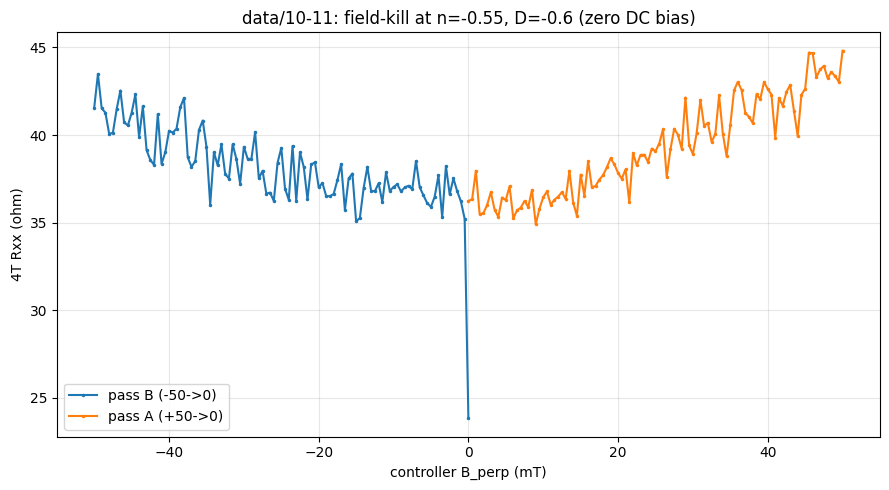

In [6]:
# Runs data/10-11 — Step 3 field-kill (Rxx vs B_perp) at the candidate, zero DC bias
def _fk(rid):
    g = run(rid)
    B = g.col_at(g.col_indices("magnet_field")[0]) * 1e3      # mT (controller)
    R = (g.col_at(g.col_indices("sr830_3_X")[0]) / 100.0) / 1e-9
    return B, R, g.col("T")
bA, rA, tA = _fk(10); bB, rB, tB = _fk(11)
print("T held at base: A[%.4f,%.4f] B[%.4f,%.4f] K" % (tA.min(), tA.max(), tB.min(), tB.max()))
print("Rxx far-field ~%.0f ohm; near controller-0 ~%.0f ohm (pristine zero-field dip was ~7 ohm)" %
      (np.median(np.concatenate([rA[bA > 40], rB[bB < -40]])), min(rA.min(), rB.min())))
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(bB, rB, ".-", ms=3, label="pass B (-50->0)")
ax.plot(bA, rA, ".-", ms=3, label="pass A (+50->0)")
ax.set_xlabel("controller B_perp (mT)"); ax.set_ylabel("4T Rxx (ohm)")
ax.set_title("data/10-11: field-kill at n=-0.55, D=-0.6 (zero DC bias)")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()


**Read:** A symmetric V centered at controller ≈ 0 mT — Rxx rises with |B⊥| on both sides (~36 Ω near 0 → ~43 Ω at ±50 mT), while the normal state away from it is field-insensitive. **The low-R state is field-killed** — consistent-with SC (B_c⊥ on a ~few-tens-of-mT scale). Caveat: the 50 mT excursion left ~10 mT remanence, so controller-0 ≠ true zero and I did not cleanly recover the pristine ~7 Ω dip (a clean B_c⊥ would need degauss/thermal re-zero). T held at base across both passes (no ramp-heating artifact). 

**Constellation now (base T + field):** Rxx dip + critical-current (switching peaks at ±Ic≈15 nA) + ±D asymmetry + field-kill — four hallmarks, all consistent-with proximity SC. Remaining decisive hallmark: Ic collapse at Tc (Step 4, heat up last).

# SESSION VERDICT — zf1 bottom device (2026-06-24)

**Campaign question: does this device superconduct?**

## Candidate C1 — n = −0.55×10¹² cm⁻² (−5.5×10¹¹), D = −0.60 V/nm, holes

### 1. Verdict (STYLE strength scale)
**Consistent-with superconductivity — a compelling proximity-SC candidate (leaning strong).** The graphene–WSe₂ proximity-SC interpretation is favoured. **The failed-SC / anomalous-metal fork is explicitly unresolved** (zero-bias Rxx is low but not → 0), and the decisive T-dependence is not yet measured — so this is NOT a confident "superconductor."

### 2. Evidence (each hallmark with coordinates + benchmark)
- **Cap-ratio calibration** — CNP fit c_bg/c_tg = 1.183 (0.3% from the 1.18 geometry prior); (n,D) ratio data-backed, absolute scale still geometry-prior. [data/4]
- **4-wire Rxx dip** → ~6–7 Ω at (n=−0.55, D=−0.60, B≈0, T=34 mK), ~4× below the ~25 Ω metallic surroundings; localized. [data/6 linecut, data/9 zero-bias]
- **Critical-current nonlinearity** — dV/dI dips to ~7.5 Ω at zero bias and rises through **sharp switching peaks at ±Ic ≈ 12–15 nA** to the ~45–51 Ω normal state; symmetric, no fwd/bwd hysteresis. Ic comparable to the ~20 nA proximity reference (paper s41586-022-05446-x, Fig 1d). [data/9]
- **±D asymmetry** — the low-Rxx dip appears for D<0 (holes→WSe₂) and is replaced by a resistance PEAK at D=+0.5 (same n) — the proximity-SOC carrier-polarization signature (s41586-022-05446-x). [data/5–8]
- **Field-kill (B_c⊥)** — Rxx(B⊥) is a symmetric V centered at B≈0, suppressed by ±B⊥ on a ~few-tens-of-mT scale, while the normal state is field-insensitive. [data/10–11]

### 3. Confidence + hedges
Four corroborating hallmarks at base T + field → a compelling candidate. Hedges:
- Zero-bias Rxx is **finite (~7 Ω, not → 0)** → failed-SC / anomalous-metal fork open.
- A dV/dI peak alone is **confound-prone** (non-equilibrium criticality; QH breakdown) — corroborated here by field-kill + ±D asymmetry, but not alone decisive.
- **Ic(T)→0 at Tc not measured** — the missing minimum-constellation element.
- **B_c⊥ not cleanly quantified** — the 50 mT excursion left ~10 mT remanence, so controller-0 ≠ true zero; the pristine dip was not recovered.
- **QAH not excluded by R_xy** — no Hall pair was routed this session (config has only 4T-long 30-31 and 2T 5-4).

### 4. What would firm the call
1. **T-dependence (decisive):** Ic(T) collapse → Tc; zero-bias dV/dI(T) toward the normal-state trend. Heat up LAST (~3 h). First **re-zero the magnet** (degauss/thermal) to recover the SC optimum and quantify B_c⊥(0).
2. **Route a Hall pair (R_xy)** to exclude a QAH mimic.
3. **Lower-AC (0.5 nA) bias-spec** at the optimum — does the zero-bias floor drop? (bears on the failed-SC fork).
4. **Tight nD-map** around C1 to pin the true optimum (n,D) and the arc width.

### 5. Status
A **successful, calibrated outcome**: a compelling proximity-SC candidate with four base-T + field hallmarks, with the confirmation step (T-dependence) and the failed-SC-fork resolution explicitly identified as the remaining work. A confident "SC" call without the T-collapse and with Rxx not → 0 would be a protocol violation; this hedged call is the honest read.

*Normal-state fermiology (Landau fan / SdH) deferred — needs Tesla-scale field, out of this round's 100 mT cap.*
